# Dynamic case generation (offshore-waves forcing)

Workflow:

1. Load **goals** from the case JSON → `simulations.goals_file`.
2. Open a **processed offshore-waves** zarr (`offshore_waves` in the case JSON).
3. Build SnapWave boundary forcing per timestep (`hs`, `tp`, `wd`, `ds`).
4. Run cases (optional) and postprocess to a single time-series NetCDF.

Processed offshore data must use dims `(time, goal)` with bulk variables
`hs`, `tp`, `dir`, `spr` (see `07_Download_Process_WHACS.ipynb`).

In [1]:
import os
import sys

# Must run before any GDAL-touching import (geopandas/pyogrio, rasterio/rioxarray).
# When the kernel is launched without going through `conda activate` (e.g. VS
# Code's Jupyter extension), GDAL_DATA/PROJ_DATA are unset, and importing
# rioxarray/rasterio before geopandas.read_file() in that state leaves GDAL's
# data-path auto-discovery broken for pyogrio, raising:
#   ValueError: Found GDAL data directory at .../share/gdal but it does not
#   appear to correctly contain GDAL data files
# Setting these explicitly sidesteps the broken auto-discovery.
os.environ.setdefault("GDAL_DATA", os.path.join(sys.prefix, "share", "gdal"))
os.environ.setdefault("PROJ_DATA", os.path.join(sys.prefix, "share", "proj"))

import xarray as xr
from utils.config import (
    PATHS,
    SIMULATIONS,
    get_offshore_wave,
    goals_for_snapwave,
    load_goals,
    open_offshore_waves,
    resolve,
)
from utils.simulation.offshore_forcing import boundary_parameters
from utils.simulation.snapwave_wrappers import SnapWaveDynamicModelWrapper

## Configuration

In [2]:
offshore_name = "WHACS"  # must match an entry in the case JSON → offshore_waves
period = ["2010", "2015"]  # time slice passed to xarray .sel(time=...)

offshore_entry = get_offshore_wave(offshore_name)
templates_dir = resolve(SIMULATIONS["dynamic_templates"])
cases_dir = resolve(SIMULATIONS["dynamic_cases"])
aoi_file = resolve(PATHS["aoi_file"])
mesh_file = resolve(PATHS["mesh_file"])
goals_file = resolve(SIMULATIONS["goals_file"])
offshore_path = resolve(offshore_entry["data_path"])
raw_goals = load_goals()

print(f"offshore  : {offshore_name} → {offshore_path}")
print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"mesh      : {mesh_file}")
print(f"period    : {period}")

offshore  : WHACS → /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/WHACS/processed/Netherlands_WHACS_goal.zarr
goals     : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Goals/Netherlands_Goals.json
templates : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/templates-dynamic
cases     : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SnapWave_CASES_Dynamic
mesh      : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/GRID/UGdcsm-fm_100m2coast3d_v3_era5bnd_net.nc
period    : ['2010', '2015']


## Offshore waves → boundary forcing

In [3]:
offshore_ds = xr.concat(
    [open_offshore_waves(entry=offshore_entry).sel(time=period) for period in period],
    dim="time",
).load()
offshore_ds

<xarray.Dataset> Size: 34MB
Dimensions:   (time: 17520, goal: 10)
Coordinates:
  * time      (time) datetime64[ns] 140kB 2010-01-01 ... 2015-12-31T23:00:00
  * goal      (goal) int64 80B 1 2 3 4 5 6 7 8 9 10
    seapoint  (goal) int64 80B 2323617 2334975 2324234 ... 2326133 2326141
Data variables: (12/24)
    dir       (time, goal) float64 1MB 31.4 34.6 36.2 37.4 ... 234.2 241.0 248.2
    hs        (time, goal) float64 1MB 2.352 2.342 2.26 ... 1.92 1.716 1.554
    pdir0     (time, goal) float64 1MB 31.4 35.5 38.5 41.5 ... 232.7 239.0 246.1
    pdir1     (time, goal) float64 1MB nan 349.4 347.3 ... 330.6 332.6 331.0
    pdir2     (time, goal) float64 1MB nan nan nan nan nan ... nan nan nan nan
    pdir3     (time, goal) float64 1MB nan nan nan nan nan ... nan nan nan nan
    ...        ...
    ptp0      (time, goal) float64 1MB 7.3 7.0 6.86 6.65 ... 7.03 6.99 7.0 7.05
    ptp1      (time, goal) float64 1MB nan 11.53 11.41 ... 13.58 13.59 13.54
    ptp2      (time, goal) float64 1MB nan nan nan nan nan ... nan nan nan nan
    ptp3      (time, goal) float64 1MB nan nan nan nan nan ... nan nan nan nan
    spr       (time, goal) float64 1MB 26.9 29.2 30.2 29.8 ... 35.0 36.5 36.0
    tp        (time, goal) float64 1MB 7.299 6.993 6.849 ... 6.993 6.993 7.042
Attributes: (12/59)
    Conventions:                     CF-1.11 ACDD-1.3
    title:                           Wave Hindcast for the Australian Climate...
    summary:                         Wave Hindcast for the Australian Climate...
    keywords:                        WHACS, ACS, waves, ocean, coast, WWIII, ...
    id:                              BoM-CSIRO-WHACS-001
    naming_authority:                au.csiro
    ...                              ...
    geospatial_lon_max:              179.9375
    geospatial_vertical_positive:    up
    time_coverage_start:             1979-01-01T00:00:00
    time_coverage_end:               1979-01-31T23:00:00
    time_coverage_duration:          P30DT23H0M0S
    time_coverage_resolution:        P0DT1H0M0S

In [4]:
metamodel_parameters = boundary_parameters(offshore_ds)
list(metamodel_parameters.keys())

['hs_goals', 'tp_goals', 'dir_goals', 'spr_goals', 'tref']

In [5]:
import numpy as np

n_cases = len(metamodel_parameters["tref"])
metamodel_parameters["save_map"] = np.random.choice(
    [True, False], size=n_cases, p=[0.05, 0.95]
).tolist()
sum(metamodel_parameters["save_map"]), n_cases

(884, 17520)

## SnapWave wrapper

Create the wrapper, then run `plot_configuration()` for a **pre-run diagnostic**:
left side = domain map + observed direction-range bars per goal; right side = text summary.
Each case is one timestep with **all goals forced** on the boundary.
Review this before `build_cases()`.

In [6]:
wrapper = SnapWaveDynamicModelWrapper(
    templates_dir=str(templates_dir),
    metamodel_parameters=metamodel_parameters,
    fixed_parameters={"gridfile": str(mesh_file)},
    output_dir=str(cases_dir),
    aoi_file=str(aoi_file),
    goals_config=goals_for_snapwave(raw_goals),
)
wrapper

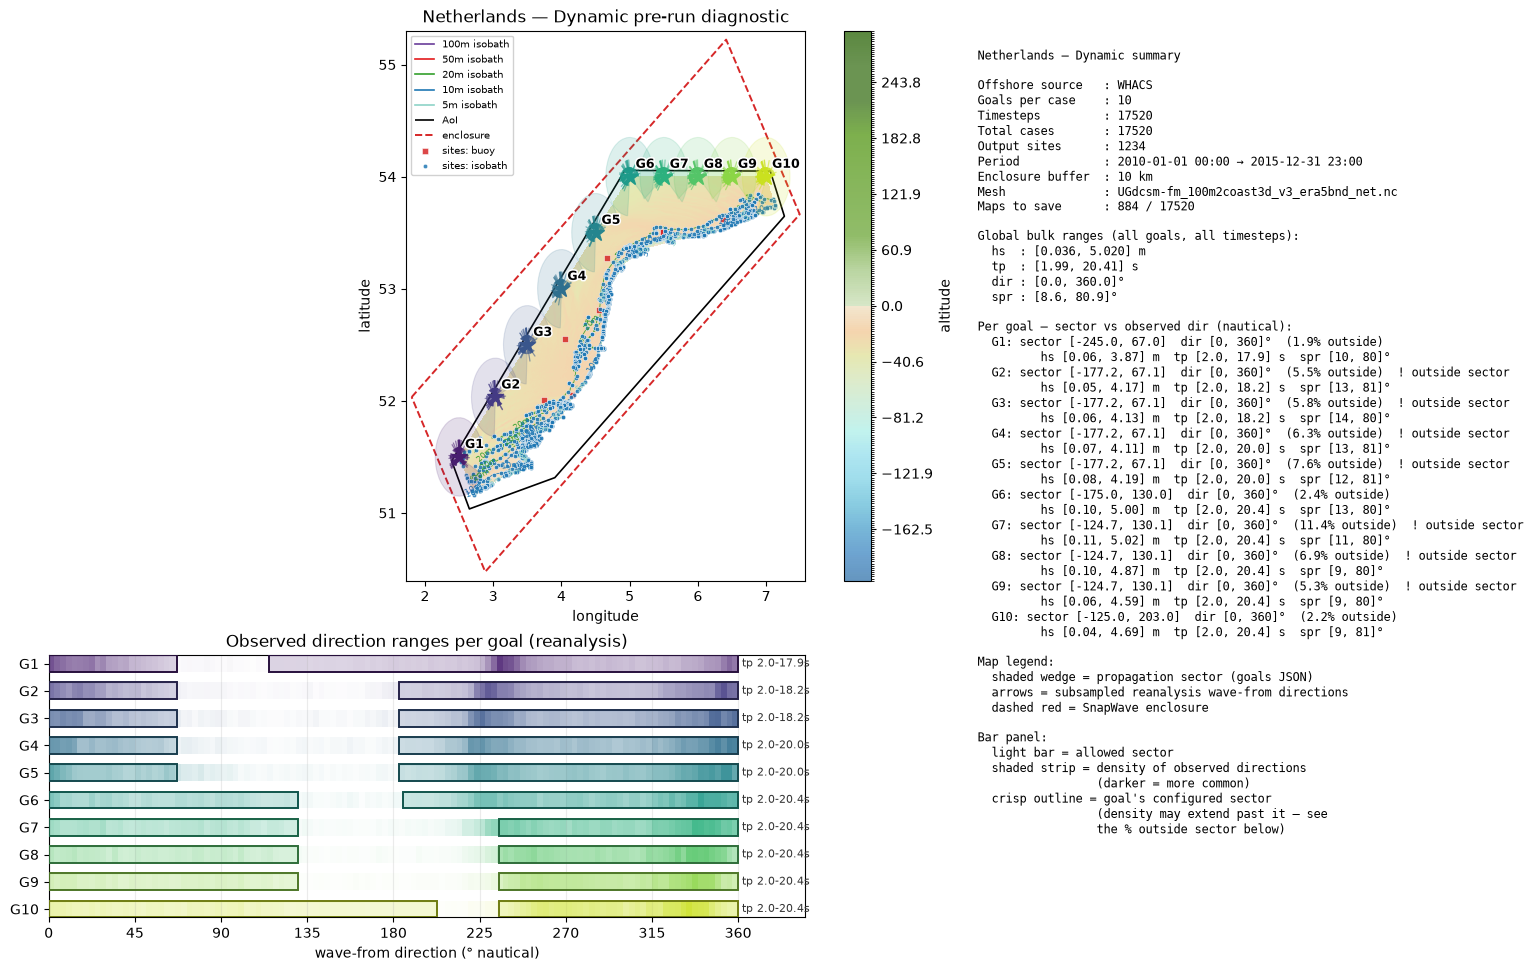

In [7]:
fig = wrapper.plot_configuration(offshore=offshore_ds, offshore_name=offshore_name)
# fig.savefig("dynamic_setup_check.png", dpi=150, bbox_inches="tight")

## Build, run, postprocess

In [8]:
wrapper.load_cases(cases_name_format=lambda ctx: f"{ctx.get('tref')}")

In [9]:
# Save all cases directories to a text file for sbatch array submission
# wrapper.cases_dir_to_txt()

In [ ]:
# wrapper.run_cases_in_background(
#     launcher="""
# module use /nfs/software/geocean/modulefiles
# module load snapwave
# snapwave
# rm snapwave.upw
# """,
#     num_workers=3,
#     cases_to_run=[144, 454, 16100],
# )

In [31]:
wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    17520
Name: count, dtype: int64

## Inspect finished cases

Post-run diagnostic (reads directly from the case folder):

- top row: full-width domain `tripcolor` map when `save_map=True` for that timestep
- bottom 2×2: `hs`, `tp`, `dir`, `spr` at output sites
- title/subtitle: case id + boundary forcing summary

Customize colormaps via `CasePlotStyle(cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"})`.

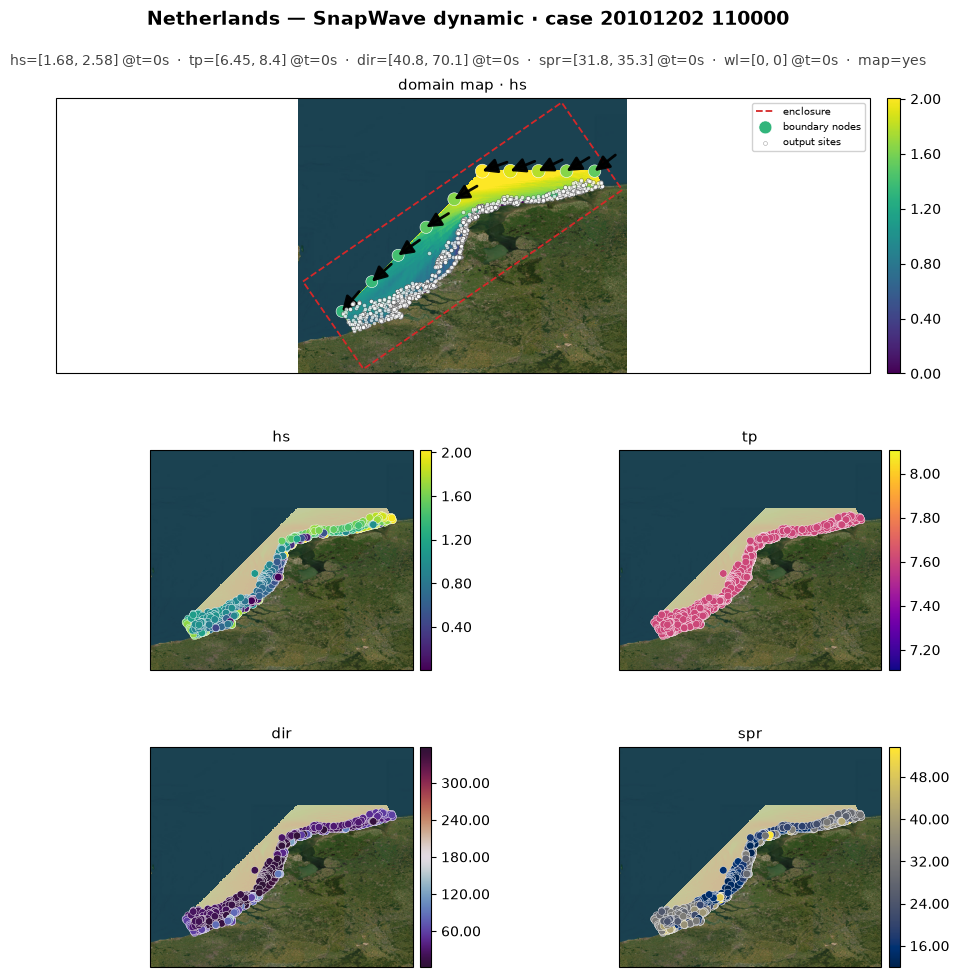

In [15]:
from utils.viz.snapwave_case_plots import CasePlotStyle

style = CasePlotStyle(
    cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"}
)
wrapper.plot_case(
    "SnapWave_CASES_Dynamic/20101202 110000", style=style, show_satellite=True
);

In [ ]:
result = wrapper.postprocess_cases()
out_nc = cases_dir / f"Dynamic_Cases_{offshore_name}_{'-'.join(period)}.nc"
result.to_netcdf(out_nc)

In [37]:
import xarray as xr

xr.open_dataset(out_nc).load().nbytes * 1e-9  # GB

0.34627716000000003